# This notebook will act as our workflow, where we can map out the proper queries needed for the data visualizations for our report.

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import kagglehub
import seaborn as sns
import missingno as msno
from data_profiling import ProfileReport
import statsmodels.formula.api as smf
plt.style.use('fivethirtyeight')
import pyarrow as pa
import fastparquet

pd.set_option('display.max_columns', None)

In [3]:
gold_df = pd.read_parquet("../data/processed/gold_df.parquet")

# Performance Snapshot Metrics

In [4]:
gold_df["exam_score"].mean()

np.float64(67.25211665098777)

In [5]:
gold_df.shape

(6378, 20)

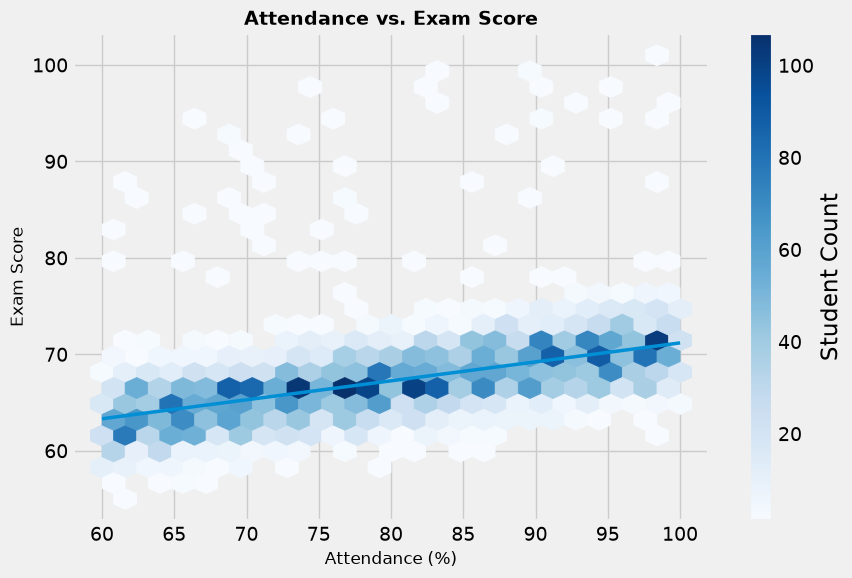

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

plt.hexbin(
    gold_df["attendance"],
    gold_df["exam_score"],
    gridsize=25,
    cmap="Blues",
    mincnt=1
)

plt.colorbar(label="Student Count")

# Regression line
z = np.polyfit(
    gold_df["attendance"],
    gold_df["exam_score"],
    1
)

p = np.poly1d(z)

x_vals = np.linspace(
    gold_df["attendance"].min(),
    gold_df["attendance"].max(),
    100
)

plt.plot(
    x_vals,
    p(x_vals),
    linewidth=2.5
)

plt.title(
    "Attendance vs. Exam Score",
    fontsize=14,
    weight="bold"
)

plt.xlabel("Attendance (%)", fontsize=12)
plt.ylabel("Exam Score", fontsize=12)

plt.tight_layout()
plt.show()